# 03 · SQL Funnel Deep-Dive (DuckDB)

**Goal:** test hypotheses H1–H5 from the EDA with SQL, find the weakest funnel step for every segment,
and put a **₹ value** on each opportunity so the team knows what to fix first.

All queries live as standalone `.sql` files in [`/sql`](../sql) and run unchanged in the DuckDB CLI:
```bash
duckdb -c ".read sql/00_setup_views.sql" -c ".read sql/02_segment_funnel.sql"
```

| File | Question | SQL techniques |
|---|---|---|
| `01_overall_funnel.sql` | Where is the biggest leak? | `UNPIVOT`, `LAG`, `FIRST_VALUE` |
| `02_segment_funnel.sql` | How does every segment's funnel compare? | `UNPIVOT` dimensions, window `SUM() OVER (PARTITION BY)` |
| `03_weakest_step_by_segment.sql` | Which step is each segment's weak point? | multi-CTE, `RANK()`, `QUALIFY` |
| `04_time_between_steps.sql` | Do mobile users struggle or just leave? | `FILTER` aggregates, `QUANTILE_CONT` |
| `05_weekly_trend.sql` | Is conversion really improving? | `DATE_TRUNC`, moving average frame, `LAG` |
| `06_payment_failures.sql` | Which payment methods fail? | conditional aggregation |
| `07_opportunity_sizing.sql` | What is each fix worth in ₹? | CTE per hypothesis, `UNION ALL`, `RANK()` |

In [1]:
import os
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SQL, IMG = ROOT / "sql", ROOT / "images"
con = duckdb.connect()

def run(name):
    """Run a .sql file from /sql. Paths inside the files are relative to the repo root."""
    cwd = os.getcwd(); os.chdir(ROOT)
    try:
        return con.sql((SQL / name).read_text()).df()
    finally:
        os.chdir(cwd)

os.chdir(ROOT); con.execute((SQL / "00_setup_views.sql").read_text())   # register views
sns.set_theme(style="whitegrid"); BLUE, GREY, RED = "#2563eb", "#9ca3af", "#dc2626"
print((SQL / "02_segment_funnel.sql").read_text())

-- 02 · Funnel by every segment in ONE query
-- Technique: UNPIVOT the segment columns so device / channel / city tier / speed / visitor type
-- become rows (dimension, segment). One GROUP BY then produces every segment funnel.
WITH base AS (
    SELECT
        device,
        channel,
        city_tier,
        CASE WHEN page_load_ms > 3000 THEN 'slow (>3s)' ELSE 'fast (<=3s)' END AS page_speed,
        CASE WHEN is_returning = 1 THEN 'returning' ELSE 'new' END            AS visitor_type,
        product_view, add_to_cart, checkout_start, payment_attempt, purchase, revenue_inr
    FROM session_funnel
    WHERE device <> 'unknown'
),
long AS (
    UNPIVOT base
    ON device, channel, city_tier, page_speed, visitor_type
    INTO NAME dimension VALUE segment
)
SELECT
    dimension,
    segment,
    COUNT(*)                                                         AS sessions,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY dimension), 1) AS share_pct,
    ROUND(100.0 * AVG(p

## 1 · Overall funnel

In [2]:
run("01_overall_funnel.sql")

,step,stage,sessions,prev_stage_sessions,step_conversion_pct,of_all_sessions_pct,lost_at_step
0,0,session,80000.0,NaN,NaN,100.00,NaN
1,1,product_view,56002.0,80000.0,70.0,70.00,23998.0
2,2,add_to_cart,8523.0,56002.0,15.2,10.65,47479.0
3,3,checkout_start,4676.0,8523.0,54.9,5.85,3847.0
4,4,payment_attempt,3120.0,4676.0,66.7,3.90,1556.0
5,5,purchase,2734.0,3120.0,87.6,3.42,386.0


Confirms the EDA: the **view → cart** step loses the most people (47k), but that step is a
merchandising problem spread across every product page. Checkout and payment lose fewer people,
but those people had *already decided to buy*.

## 2 · Every segment's funnel in one query

In [3]:
seg = run("02_segment_funnel.sql")
seg

,dimension,segment,sessions,share_pct,view_rate_pct,view_to_cart_pct,cart_to_checkout_pct,checkout_to_payment_pct,payment_success_pct,cvr_pct,revenue_per_session
0,channel,organic_search,21426,27.1,73.3,15.1,55.3,68.9,86.4,3.64,59.1
1,channel,paid_social,17459,22.1,55.8,11.7,53.8,65.5,88.8,2.04,31.5
2,channel,paid_search,14369,18.2,76.0,16.5,54.1,67.0,88.7,4.02,68.8
3,channel,direct,11769,14.9,75.3,16.4,56.0,64.7,88.6,3.97,67.8
4,channel,email,6141,7.8,82.9,19.0,55.2,65.9,86.4,4.95,77.6
5,channel,referral,3950,5.0,66.2,12.8,51.8,67.6,90.6,2.68,43.1
6,channel,affiliate,3941,5.0,62.6,14.0,56.8,64.8,85.8,2.77,43.3
7,city_tier,tier_1,37882,47.9,70.8,15.7,55.0,67.5,88.2,3.64,58.2
8,city_tier,tier_2,25353,32.1,70.0,15.1,53.9,66.3,85.9,3.24,54.3
9,city_tier,tier_3,15820,20.0,68.4,14.1,56.0,65.5,89.5,3.17,52.9


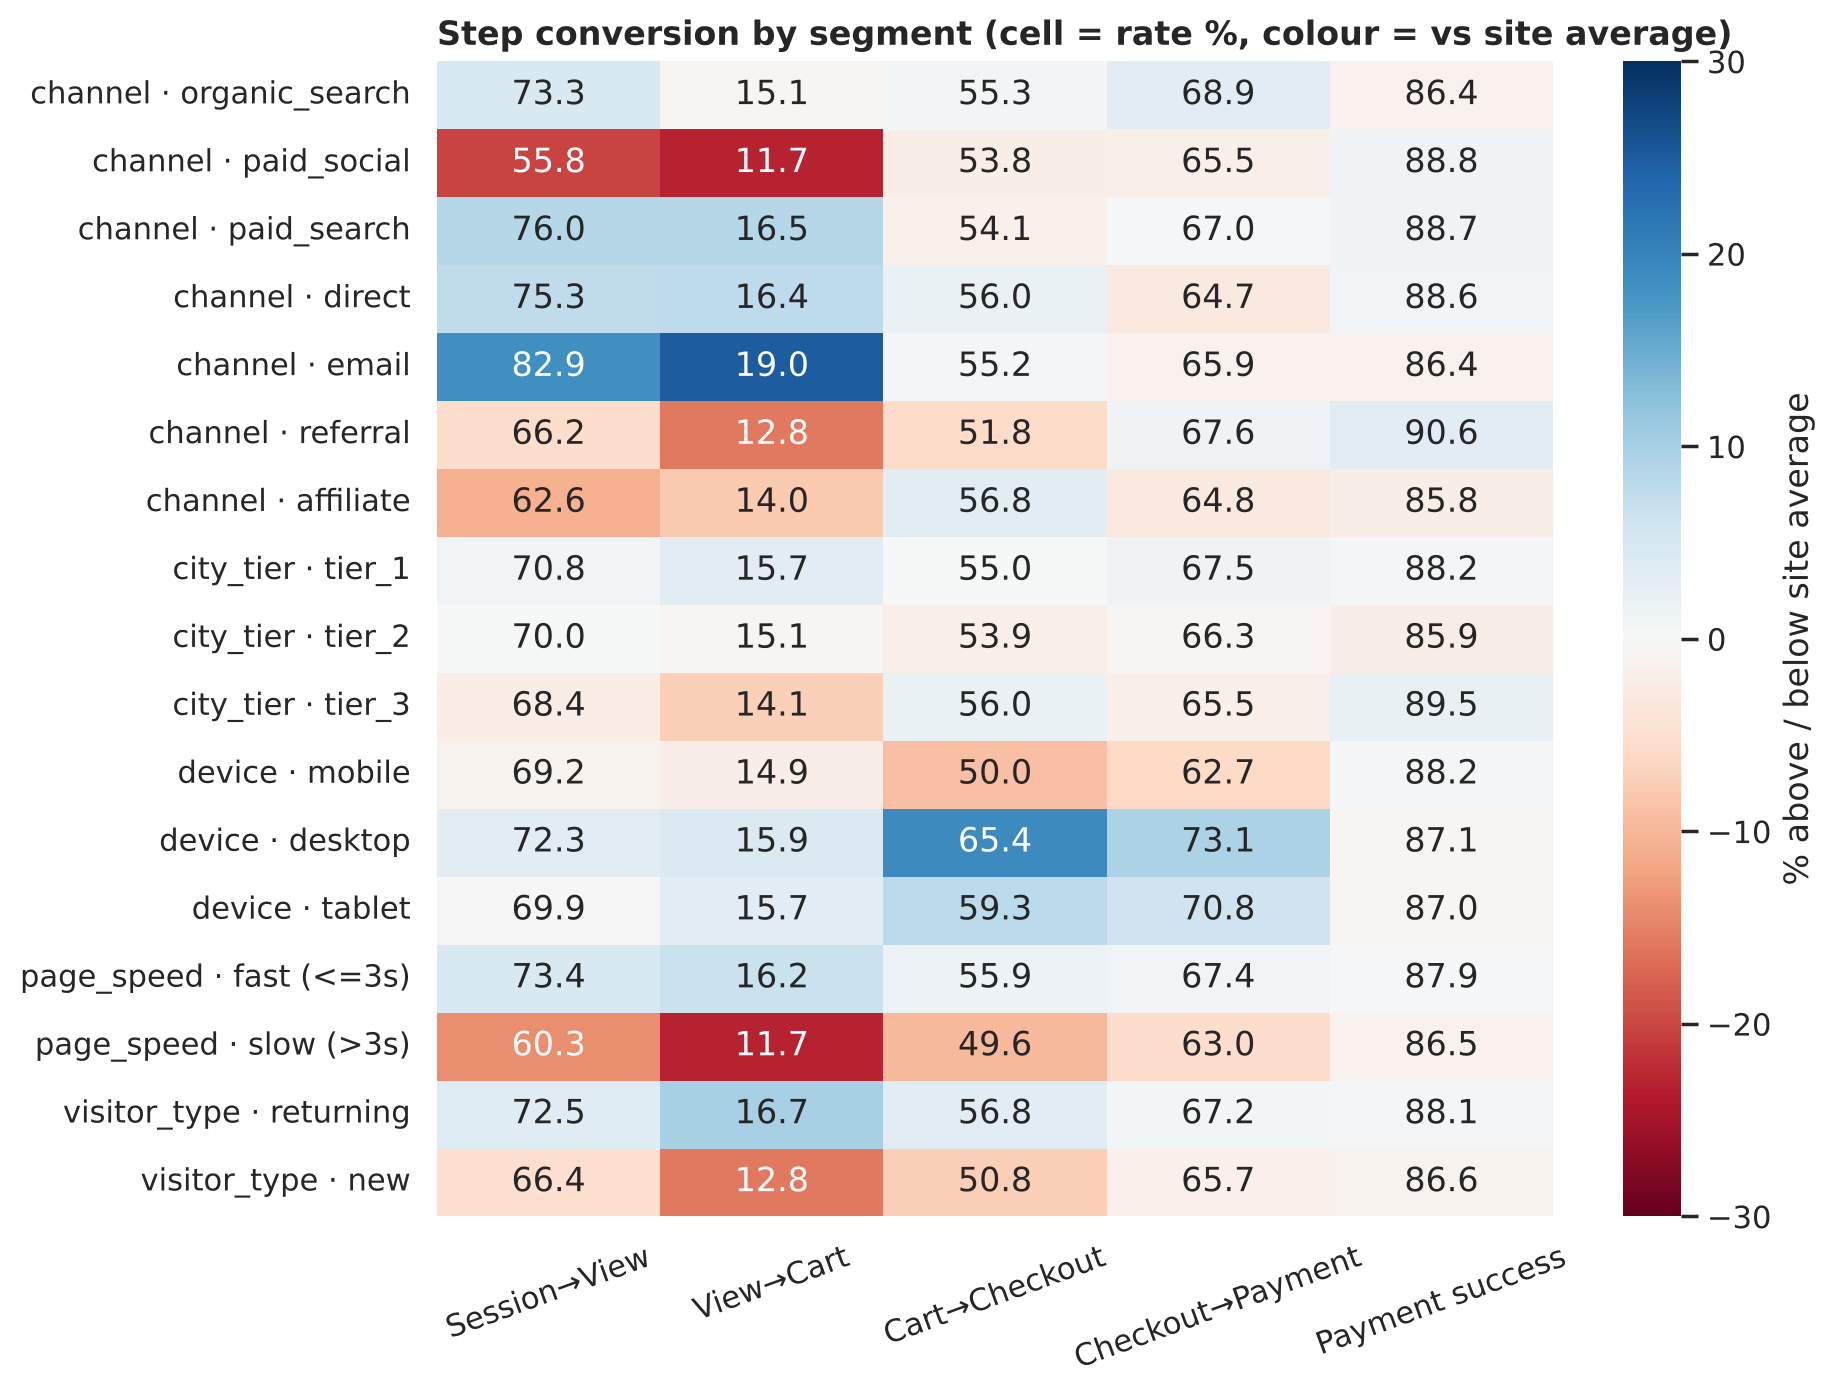

In [4]:
rate_cols = ["view_rate_pct", "view_to_cart_pct", "cart_to_checkout_pct", "checkout_to_payment_pct", "payment_success_pct"]
h = seg.assign(label=seg.dimension + " · " + seg.segment).set_index("label")[rate_cols]
site = pd.Series({"view_rate_pct": 70.0, "view_to_cart_pct": 15.2, "cart_to_checkout_pct": 54.9,
                  "checkout_to_payment_pct": 66.7, "payment_success_pct": 87.6})  # from 01_overall_funnel
idx = (h / site - 1) * 100
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(idx, cmap="RdBu", center=0, vmin=-30, vmax=30, annot=h.round(1), fmt="", ax=ax,
            cbar_kws={"label": "% above / below site average"})
ax.set_xticklabels(["Session→View", "View→Cart", "Cart→Checkout", "Checkout→Payment", "Payment success"], rotation=20)
ax.set_ylabel(""); ax.set_title("Step conversion by segment (cell = rate %, colour = vs site average)", loc="left", fontweight="bold")
fig.savefig(IMG / "08_segment_heatmap.png", dpi=150, bbox_inches="tight"); plt.show()

**Reading the heatmap (red = worse than site average):**
* **Mobile (H1 ✅ confirmed):** normal until the cart, then clearly red at *cart → checkout* (50% vs 65% on desktop)
  and *checkout → payment* (63% vs 73%). The problem is the checkout flow, not mobile shoppers' interest.
* **Slow pages (H4 ✅):** red at *every* early step, with CVR **1.90% vs 3.94%**. Slow sessions lose people before they
  even see a product.
* **Paid social (H3 ✅):** weakest at the top: only 56% view a product and 11.7% of viewers add to cart. Once in the cart,
  paid-social users behave like everyone else. The issue is **traffic quality / landing-page match**, not checkout.
* **City tier:** small differences (3.17%–3.64%); not a priority.

## 3 · The single weakest step for each segment

In [5]:
run("03_weakest_step_by_segment.sql")

,dimension,segment,sessions,weakest_step,segment_rate_pct,site_rate_pct,vs_site_pct
0,channel,paid_social,17459,view_to_cart,11.7,15.2,-23.0
1,channel,referral,3950,view_to_cart,12.8,15.2,-16.1
2,channel,affiliate,3941,session_to_view,62.6,70.0,-10.6
3,device,mobile,53941,cart_to_checkout,50.0,54.9,-8.9
4,channel,direct,11769,checkout_to_payment,64.7,66.7,-3.1
5,channel,paid_search,14369,cart_to_checkout,54.1,54.9,-1.5
6,channel,email,6141,payment_success,86.4,87.6,-1.4
7,channel,organic_search,21426,payment_success,86.4,87.6,-1.4
8,device,tablet,4682,payment_success,87.0,87.6,-0.7
9,device,desktop,20432,payment_success,87.1,87.6,-0.6


## 4 · Do mobile users struggle, or just leave?

In [6]:
run("04_time_between_steps.sql")

,device,orders,median_land_to_cart_min,median_cart_to_checkout_min,median_checkout_to_payment_min,median_total_min,p90_total_min
0,mobile,1533,2.2,1.0,0.8,5.5,10.1
1,desktop,980,2.2,1.1,0.8,5.5,10.3
2,tablet,188,2.1,1.0,0.9,5.2,9.8
3,unknown,33,2.5,0.7,0.7,5.0,8.1


Among people who **do** buy, mobile and desktop take the same time (~5.5 min median) at every step.
So mobile buyers aren't slowed down by a hard-to-use form; the ones who drop **give up and leave**.
That suggests friction like too many steps, forced sign-up or address entry, which is exactly what a one-page checkout removes.

## 5 · Is conversion really improving? (a trap)

In [7]:
wk = run("05_weekly_trend.sql")
wk

,week,sessions,orders,returning_pct,cvr_pct,cvr_4wk_avg_pct,sessions_wow_pct,revenue_inr
0,2026-07-27,1758,48.0,9.2,2.73,2.73,NaN,86600.0
1,2026-08-03,5723,135.0,23.5,2.36,2.54,225.5,220083.0
2,2026-08-10,5794,176.0,37.3,3.04,2.71,1.2,295878.0
3,2026-08-17,5826,159.0,43.9,2.73,2.71,0.6,250991.0
4,2026-08-24,5752,178.0,51.9,3.09,2.81,-1.3,308236.0
5,2026-08-31,5685,173.0,56.0,3.04,2.98,-1.2,303917.0
6,2026-09-07,5724,184.0,61.0,3.21,3.02,0.7,274489.0
7,2026-09-14,5636,220.0,64.6,3.90,3.31,-1.5,379274.0
8,2026-09-21,5696,210.0,68.0,3.69,3.46,1.1,355782.0
9,2026-09-28,5843,238.0,69.9,4.07,3.72,2.6,385372.0


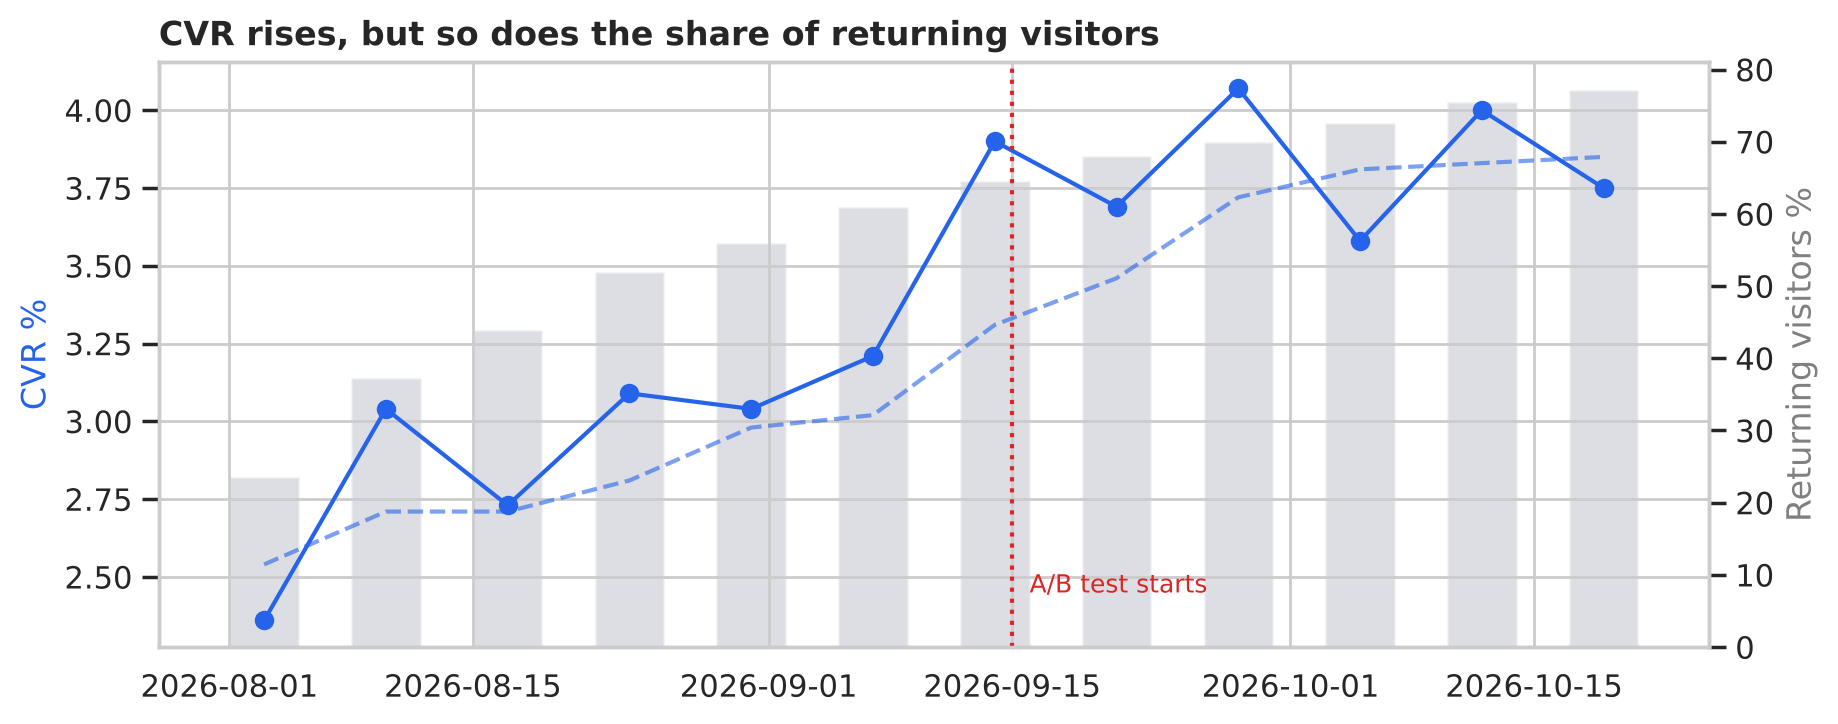

In [8]:
fig, ax1 = plt.subplots(figsize=(10, 3.8))
w = wk.iloc[1:-1]  # drop the partial first and last weeks
ax1.plot(w.week, w.cvr_pct, color=BLUE, marker="o", label="Weekly CVR %")
ax1.plot(w.week, w.cvr_4wk_avg_pct, color=BLUE, ls="--", alpha=.6, label="4-week avg")
ax1.set_ylabel("CVR %", color=BLUE)
ax2 = ax1.twinx(); ax2.bar(w.week, w.returning_pct, width=4, color=GREY, alpha=.35, label="Returning visitors %")
ax2.set_ylabel("Returning visitors %", color="grey"); ax2.grid(False)
ax1.axvline(pd.Timestamp("2026-09-15"), color=RED, ls=":"); ax1.text(pd.Timestamp("2026-09-16"), 2.45, "A/B test starts", color=RED, fontsize=9)
ax1.set_zorder(ax2.get_zorder() + 1); ax1.patch.set_visible(False)
ax1.set_title("CVR rises, but so does the share of returning visitors", loc="left", fontweight="bold")
fig.savefig(IMG / "09_weekly_trend.png", dpi=150, bbox_inches="tight"); plt.show()

**Why this matters:** conversion climbs from ~2.4% to ~4.0%. A naive before/after comparison would credit the new
checkout with all of it. But the **returning-visitor share climbs from 23% to 79%** over the same weeks.
Partly that's an artefact (we only see data from 1 Aug, so *everyone* looks "new" at first), and returning visitors convert
~66% better. **Before/after comparisons are unreliable here; that's why the A/B test (Notebook 04) compares
control and variant over the *same* weeks.**

Note: the first and last weeks are partial and excluded from the chart.

## 6 · Payment failures by method

In [9]:
run("06_payment_failures.sql")

,payment_method,attempts,share_of_attempts_pct,successes,failures,success_rate_pct,mobile_success_pct,desktop_success_pct
0,upi,1679,53.8,1502.0,177.0,89.5,90.1,88.5
1,card,816,26.2,652.0,164.0,79.9,80.2,80.8
2,cod,466,14.9,442.0,24.0,94.8,95.3,94.0
3,wallet,159,5.1,138.0,21.0,86.8,86.8,86.0


Card success is ~80% on both mobile and desktop, so it's a **payment-gateway issue**, not a device one.
164 failed card attempts in the quarter vs 177 for UPI, despite UPI having twice the volume.

## 7 · Opportunity sizing: what is each fix worth?
Every lever assumes we **close half the gap** to a realistic benchmark (desktop, same-device fast pages, site average, UPI).
H4 is computed *within* each device, so it isn't double-counting the mobile effect.

In [10]:
opp = run("07_opportunity_sizing.sql")
opp

,lever,assumption,extra_orders_per_quarter,extra_revenue_lakh_per_quarter,extra_revenue_lakh_per_year,priority
0,H1 Mobile checkout UX,mobile cart->payment rate moves halfway to des...,403.0,6.60,26.4,1
1,H4 Page speed (<3s),slow sessions close half the CVR gap to fast s...,163.0,2.67,10.7,2
2,H3 Paid social landing pages,paid-social product-view rate moves halfway to...,46.0,0.75,3.0,3
3,H5 Card payment success,card success rate moves halfway to UPI,39.0,0.64,2.6,4


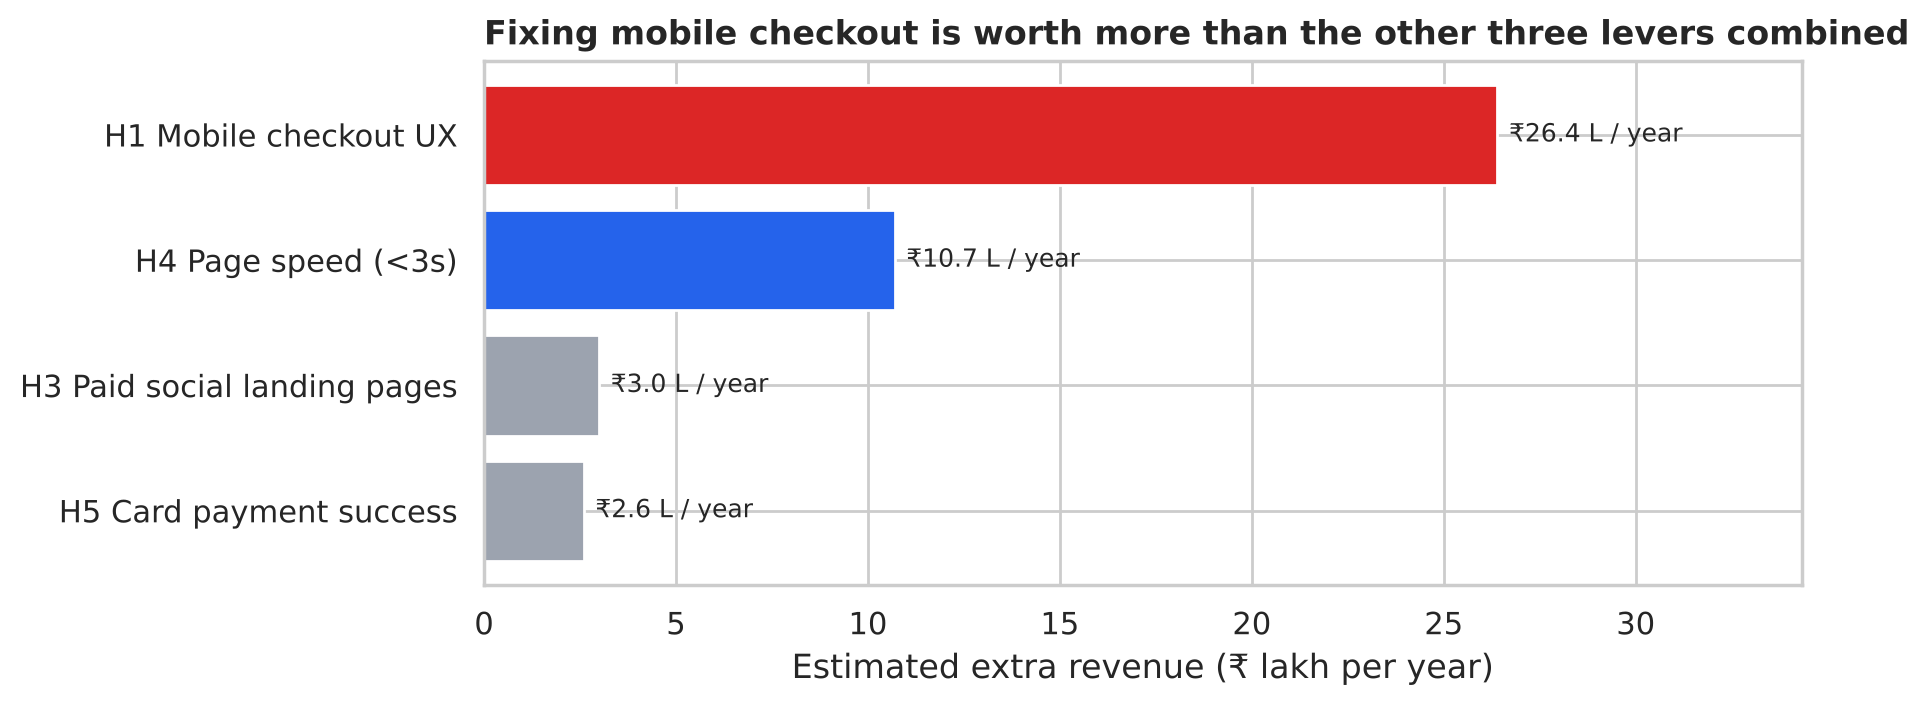

In [11]:
fig, ax = plt.subplots(figsize=(8.5, 3.4))
o2 = opp.sort_values("extra_revenue_lakh_per_year")
ax.barh(o2.lever, o2.extra_revenue_lakh_per_year, color=[GREY, GREY, BLUE, RED][:len(o2)])
for y, v in enumerate(o2.extra_revenue_lakh_per_year):
    ax.text(v + 0.3, y, f"₹{v:.1f} L / year", va="center", fontsize=9)
ax.set_xlabel("Estimated extra revenue (₹ lakh per year)"); ax.set_xlim(0, o2.extra_revenue_lakh_per_year.max() * 1.3)
ax.set_title("Fixing mobile checkout is worth more than the other three levers combined", loc="left", fontweight="bold")
fig.savefig(IMG / "10_opportunity_sizing.png", dpi=150, bbox_inches="tight"); plt.show()

## Conclusions
| Priority | Lever | Est. value | Evidence |
|---|---|---|---|
| 1 | **Mobile checkout UX** (H1) | ~₹26 L / year (~400 orders a quarter) | Mobile cart→payment 31% vs 48% desktop; buyers take equal time, so leavers are quitting, not struggling |
| 2 | **Page speed under 3s** (H4) | ~₹11 L / year | CVR roughly halves above 3s on both mobile and desktop (same-device comparison); a third of mobile sessions are slow |
| 3 | **Paid social landing pages** (H3) | ~₹3 L / year (+ ad-spend savings) | Top-of-funnel weakness only; cart behaviour is normal |
| 4 | **Card payment success** (H5) | ~₹2.6 L / year | 80% vs 90% UPI; cheap gateway/retry fix |

The opportunities overlap (slow pages are mostly mobile), so **don't add them up**.
**Next:** H2, whether the one-page checkout actually fixes H1, is tested in Notebook 04.